# EDA & Feature Engineering — German Credit Data
Exploration of the raw data and the reasoning behind every engineered feature.
The final transformations live in `features.py`, so all models train on exactly what is shown here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from features import load_raw, engineer, NUM, CAT, PROTECTED

sns.set_theme(style="whitegrid")
df = load_raw()
df.head()

,checking,duration,history,purpose,amount,savings,employment,installment_rate,personal_status,debtors,...,property,age,other_plans,housing,n_credits,job,n_dependents,telephone,foreign_worker,default
0,<0,6,critical,radio/tv,1169,unknown/none,>=7y,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,0
1,0-200,48,existing paid,radio/tv,5951,<100,1-4y,2,female div/sep/mar,none,...,real estate,22,none,own,1,skilled,1,no,yes,1
2,none,12,critical,education,2096,<100,4-7y,2,male single,none,...,real estate,49,none,own,1,unskilled res,2,no,yes,0
3,<0,42,existing paid,furniture,7882,<100,4-7y,2,male single,guarantor,...,savings/insurance,45,none,free,1,skilled,2,no,yes,0
4,<0,24,past delay,new car,4870,<100,1-4y,3,male single,none,...,none,53,none,free,2,skilled,2,no,yes,1


## 1. Structure and data quality

In [2]:
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.dtypes.value_counts()

Shape: (1000, 21)
Missing values: 0
Duplicate rows: 0


str      13
int64     8
Name: count, dtype: int64

In [2]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
duration,1000.0,20.90,12.06,4.0,12.0,18.0,24.00,72.0
amount,1000.0,3271.26,2822.74,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.97,1.12,1.0,2.0,3.0,4.00,4.0
residence_since,1000.0,2.84,1.10,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.55,11.38,19.0,27.0,33.0,42.00,75.0
n_credits,1000.0,1.41,0.58,1.0,1.0,1.0,2.00,4.0
n_dependents,1000.0,1.16,0.36,1.0,1.0,1.0,1.00,2.0
default,1000.0,0.30,0.46,0.0,0.0,0.0,1.00,1.0


## 2. Target
`default` = 1 for bad credit (raw code 2). Imbalanced 70/30, so accuracy is misleading — we use AUC, precision/recall
and stratified splits throughout.

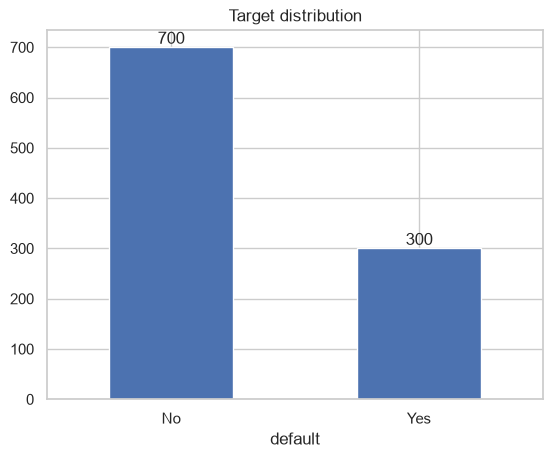

Default rate: 30.0%


In [4]:
counts = df["default"].value_counts().rename({0: "No", 1: "Yes"})
ax = counts.plot.bar(rot=0, title="Target distribution")
ax.bar_label(ax.containers[0])
plt.show()
print(f"Default rate: {df['default'].mean():.1%}")

## 3. Numeric variables — distributions and skew

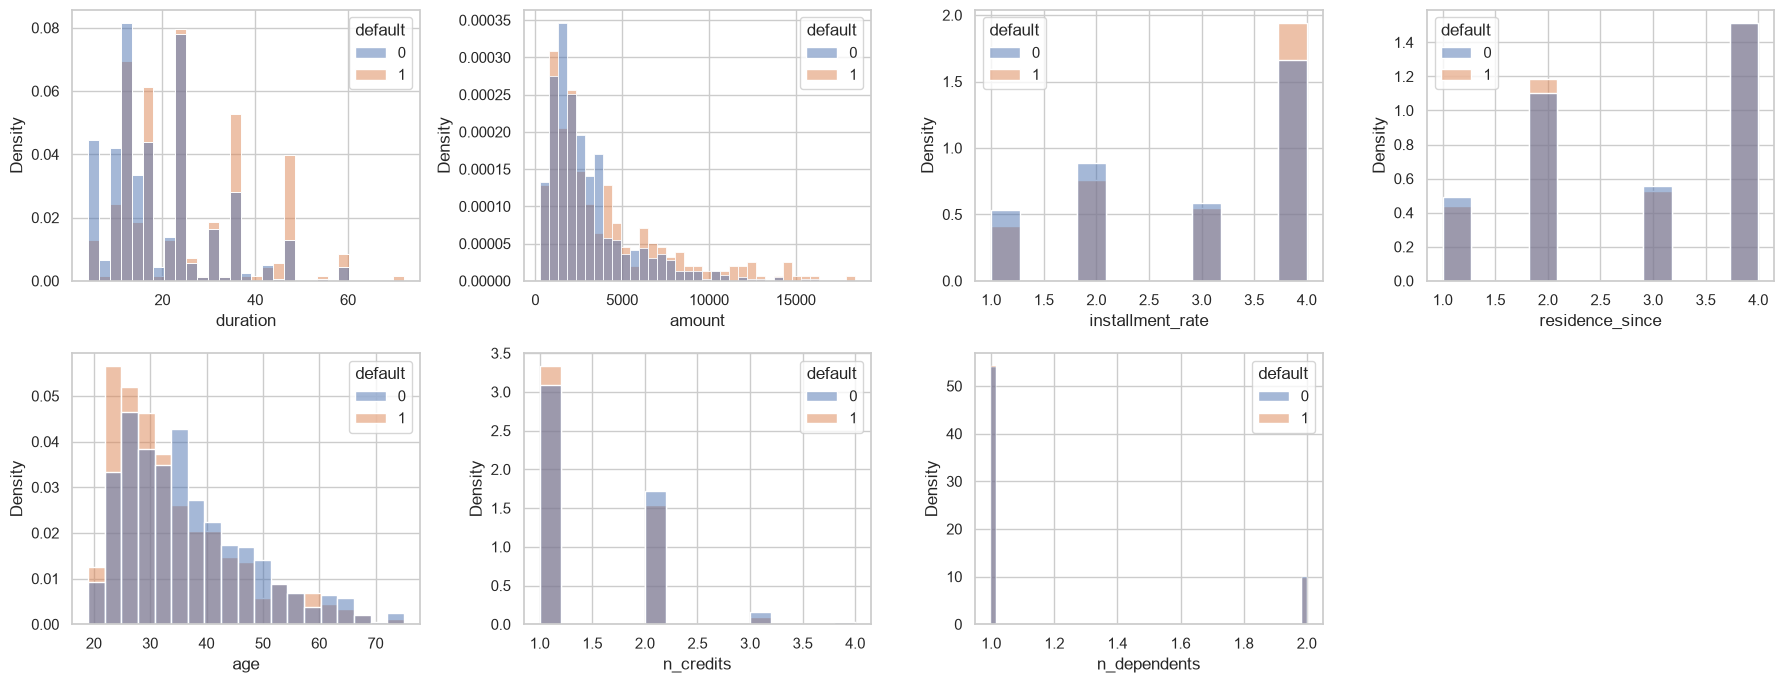

,skew
duration,1.09
amount,1.95
installment_rate,-0.53
residence_since,-0.27
age,1.02
n_credits,1.27
n_dependents,1.91


In [5]:
num_raw = ["duration", "amount", "installment_rate", "residence_since", "age", "n_credits", "n_dependents"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flat, num_raw):
    sns.histplot(data=df, x=col, hue="default", stat="density", common_norm=False, ax=ax)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()
df[num_raw].skew().round(2).rename("skew").to_frame()

## 4. Outliers
`amount`, `duration` and `age` are right-skewed with long upper tails.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["amount", "duration", "age"]):
    sns.boxplot(data=df, x="default", y=col, ax=ax)

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return ((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).sum()

plt.tight_layout()
plt.show()
df[["amount", "duration", "age"]].apply(iqr_outliers).rename("IQR outliers").to_frame()

**Decision:** the outliers are plausible loans (large amounts, long terms, older borrowers), not data errors,
and with only 1,000 rows dropping them throws away signal. We keep them and log-transform `amount` to reduce skew
instead of clipping.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["amount"], ax=axes[0]).set_title(f"amount (skew {df['amount'].skew():.2f})")
sns.histplot(np.log(df["amount"]), ax=axes[1]).set_title(f"log(amount) (skew {np.log(df['amount']).skew():.2f})")
plt.tight_layout()
plt.show()

## 5. Categorical variables — default rate by category

In [ ]:
def bad_rate_plot(data, cols, ncols=3):
    nrows = -(-len(cols) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows))
    for ax, col in zip(axes.flat, cols):
        stats = data.groupby(col)["default"].agg(["mean", "size"]).sort_values("mean")
        ax.barh(stats.index.astype(str), stats["mean"])
        ax.axvline(data["default"].mean(), color="r", ls="--")
        for i, n in enumerate(stats["size"]):
            ax.text(stats["mean"].iloc[i], i, f" n={n}", va="center", fontsize=8)
        ax.set_title(col)
        ax.set_xlabel("default rate")
    for ax in axes.flat[len(cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

bad_rate_plot(df, ["checking", "history", "savings", "employment", "purpose", "property",
                   "housing", "other_plans", "debtors"])

Key observations:
- `checking` is the strongest single signal: overdrawn accounts (<0) default far more than applicants with no checking account.
- `history` is counter-intuitive: "critical" accounts default *least* (≈17%) while "all paid back" default *most* (≈57–62%). This is a known quirk of this dataset (likely selection bias in who was granted credit) and must be flagged when interpreting coefficients/SHAP.
- Several `purpose` levels have very few rows (n < 25), which makes their one-hot coefficients unstable.

In [ ]:
df['purpose'].value_counts()

## 6. Correlation between numeric variables

In [ ]:
sns.heatmap(df[num_raw + ["default"]].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman correlation")
plt.show()

## 7. Feature engineering

The dataset has **no income or existing-debt field**, so true loan-to-income and debt-to-income ratios cannot be computed.
We build the closest available proxies and state this limitation in the report.

| Feature | Definition | Rationale |
|---|---|---|
| `log_amount` | log(amount) | removes right skew (≈1.95 → ≈0.1) |
| `monthly_payment` / `log_monthly_payment` | amount / duration | repayment size per month — affordability proxy in place of loan-to-income |
| `installment_rate` | kept as given | instalment as % of disposable income — the dataset's only income-relative measure (debt-to-income proxy) |
| `purpose_grp` | appliances, repairs, retraining, vacation, other → "other" | merges rare levels (n < 25) |
| `employment_grp` | <1y/unemployed, 1-4y, >=4y | employment categories; merges the small "unemployed" group |
| `sex`, `age_group` | split out of `personal_status`; age < 25 | **not model inputs** — kept for the fairness analysis |

`personal_status` (mixes sex and marital status) and `foreign_worker` are excluded from the model as protected attributes.

In [ ]:
fe = engineer(df)
fe[["log_amount", "monthly_payment", "log_monthly_payment"]].describe().T.round(2)

In [ ]:
fe["payment_quintile"] = pd.qcut(fe["monthly_payment"], 5)
bad_rate_plot(fe, ["payment_quintile", "employment_grp", "purpose_grp", "installment_rate", "age_group", "sex"])

Collinearity check on the final numeric inputs — `log_amount`, `duration` and `log_monthly_payment` are related by construction,
so we rely on regularisation (and report it) rather than dropping one.

In [ ]:
sns.heatmap(fe[NUM].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of model numeric features")
plt.show()

## 8. Protected attributes (for the fairness analysis)

In [ ]:
for col in PROTECTED:
    display(fe.groupby(col)["default"].agg(n="size", default_rate="mean").round(3))

Notes: `sex` is only partly identifiable (female single, A95, never appears); only 37 applicants are non-foreign workers,
so fairness results on that attribute will be noisy. Under-25s default noticeably more (≈41% vs ≈28%).

## 9. Final model inputs

In [ ]:
print(f"Numeric ({len(NUM)}):", NUM)
print(f"Categorical ({len(CAT)}):", CAT)
print("Excluded from model:", ["amount", "monthly_payment", "purpose", "employment", "personal_status"] + PROTECTED)